### For Week 4, include concepts such as logistic regression and feature scaling. This homework should be submitted for peer review in the assignment titled 4.3 Peer Review: Week 4 Jupyter Notebook.

Dataset: Lending Club loan data (`adarshsng/lending-club-loan-data-csv`, `loan.csv`). Target is binary loan default, which fits logistic regression. Numeric features span very different scales (loan amount ~ thousands, annual income ~ tens of thousands, interest rate ~ percent), which motivates feature scaling.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, roc_auc_score, confusion_matrix, roc_curve)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

# Lending Club loan data — binary default prediction task
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv")
csv_path = os.path.join(path, "loan.csv")

USECOLS = ['loan_status', 'loan_amnt', 'term', 'int_rate', 'grade',
           'home_ownership', 'annual_inc', 'dti', 'purpose',
           'verification_status', 'open_acc', 'revol_util']
CLOSED = ['Fully Paid', 'Charged Off', 'Default']

chunks = []
for ch in pd.read_csv(csv_path, usecols=USECOLS, chunksize=500000, low_memory=True):
    chunks.append(ch[ch['loan_status'].isin(CLOSED)])
df = pd.concat(chunks, ignore_index=True)

print(f"Closed-loan shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
display(df['loan_status'].value_counts().rename_axis('loan_status').to_frame(name='count'))
display(df.head(3))


Libraries imported successfully.
Closed-loan shape: (1303638, 12)
Columns: ['loan_amnt', 'term', 'int_rate', 'grade', 'home_ownership', 'annual_inc', 'verification_status', 'loan_status', 'purpose', 'dti', 'open_acc', 'revol_util']


,count
loan_status,
Fully Paid,1041952
Charged Off,261655
Default,31


,loan_amnt,term,int_rate,grade,home_ownership,annual_inc,verification_status,loan_status,purpose,dti,open_acc,revol_util
0,30000,36 months,22.35,D,MORTGAGE,100000.0,Source Verified,Fully Paid,debt_consolidation,30.46,11.0,37.0
1,40000,60 months,16.14,C,MORTGAGE,45000.0,Verified,Fully Paid,credit_card,50.53,18.0,64.5
2,20000,36 months,7.56,A,MORTGAGE,100000.0,Not Verified,Fully Paid,credit_card,18.92,9.0,29.9


## Part A — Data quality evaluation (added for Milestone One; runs before the original Week 4 analysis)
Before fitting any model we check the data the way a careful analyst would by hand: what is in the file, what is missing,
what is duplicated, which values are impossible, which columns would leak the answer, and what the target looks like.
Every issue found is written into a **data-quality summary table** (issue, rows affected, action) so a reader can judge
how much the cleaning could have influenced the results. The same block appears in every weekly notebook so each one runs on its own.

**Datasets (one framing: consumer credit default risk)**
* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, target = default in October 2005.

## Cell DQ-1 — Imports and loading the Lending Club audit columns
### Why are we doing this?
Everything later depends on the raw data being read correctly. We load only the ~28 columns we will audit or model instead
of all 145, because the full file is ~2.26M rows and loading everything wastes memory.
### What are we doing?
* `pandas` (`pd`) holds tables, `numpy` (`np`) does math, `matplotlib`/`seaborn` draw charts, `kagglehub` downloads/caches the Kaggle dataset.
* `pd.read_csv(..., usecols=LC_COLS)` reads only the listed columns. Four *post-outcome* columns (`total_pymnt`, `recoveries`, `last_pymnt_amnt`, `out_prncp`) are loaded **only** so we can prove later that they leak the answer and must be removed.
* `SEED = 42` fixes all random sampling so the notebook is reproducible (the seed makes results repeatable, not "correct").
### Alternatives
Reading all columns (simpler but ~5× the memory) or using a database/parquet copy (faster for repeated runs).
### What should we examine after execution?
The shape (rows × columns), the mix of data types (numbers vs text), and whether the first rows look sensible.

In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


## Result Interpretation — Lending Club load
### What did we actually get?
**2,260,668 rows × 28 audited columns**: 16 float, 9 text (`str`), 3 integer columns. In the first three rows, `id` shows `NaN`, the numbers look plausible (loan amounts 2,500–30,000; rates 13.56–18.94%), and `term` has a leading space (`" 36 months"`).
### What does it mean?
The file loaded correctly. Two things need attention right away: the identifier is empty, and text columns need parsing (`term`). These first rows are *current* loans, which is why `out_prncp` (outstanding principal) is non-zero. That previews the censoring problem handled two cells below.
### What should we do next?
Audit missingness across all 145 columns before choosing which ones to trust.

## Cell DQ-2 — Null-column audit across the full 145-column file
### Why are we doing this?
Missing data silently shrinks or biases a sample. Columns that are mostly empty cannot be used, and columns that are
100% empty are useless (including identifiers we might have wanted for duplicate checks).
### How does it work?
The file is read in chunks of 500,000 rows; for each chunk `isnull().sum()` counts missing cells per column, and the counts
are added up. Dividing by the total rows gives the **missing %** per column. Chunking keeps memory low.
### Key concept — missingness
**Missing completely at random** (safe to drop) vs **missing not at random** (dropping can bias results, e.g. income missing
more often for riskier borrowers). With very small missing % the choice barely matters; with large % it matters a lot.
### What should we examine after execution?
How many columns are fully empty, how many exceed 50% missing, and the missing % of the columns we actually model.

In [3]:
# Null audit on the FULL 145-column header (chunked so memory stays small)
null_cnt, n_rows = None, 0
for ch in pd.read_csv(LC_PATH, chunksize=500_000, low_memory=False):
    c = ch.isnull().sum(); null_cnt = c if null_cnt is None else null_cnt + c; n_rows += len(ch)
null_pct = (null_cnt / n_rows * 100).sort_values(ascending=False)
print(f"All columns: {len(null_pct)} | rows: {n_rows:,}")
print(f"Columns 100% empty: {(null_pct == 100).sum()} -> {null_pct[null_pct == 100].index.tolist()}")
print(f"Columns > 50% missing (dropped from consideration): {(null_pct > 50).sum()}")
print("\nMissing % for the columns we use:")
use_pct = null_pct.reindex([c for c in LC_COLS if c != "id"]).round(3)
print(use_pct[use_pct > 0].to_string())

All columns: 145 | rows: 2,260,668
Columns 100% empty: 3 -> ['id', 'url', 'member_id']
Columns > 50% missing (dropped from consideration): 44

Missing % for the columns we use:
emp_length              6.498
dti                     0.076
delinq_2yrs             0.001
inq_last_6mths          0.001
open_acc                0.001
pub_rec                 0.001
revol_util              0.080
total_acc               0.001
mort_acc                2.213
pub_rec_bankruptcies    0.060


## Result Interpretation — Null-column audit
### What did we actually get?
* **3 of 145 columns are 100% empty:** `id`, `url`, `member_id`.
* **44 columns are more than 50% missing.** These are mostly hardship/settlement and joint-applicant fields that only exist for some loans. None of them are used.
* Among the columns we use, missingness is small: `emp_length` 6.50%, `mort_acc` 2.21%, `revol_util` 0.080%, `dti` 0.076%, `pub_rec_bankruptcies` 0.060%, and the rest 0.001%.
### What does it mean?
* Missingness in our model columns is low enough that dropping incomplete rows loses only a few percent. Most of that comes from `mort_acc`.
* `emp_length` (6.5% missing) is excluded from the models because its missingness may not be random. Borrowers who leave it blank may differ in risk.
* The empty `id` means duplicates must be detected by comparing whole rows.
### What can we NOT conclude?
That the dropped rows are like the kept rows. With about 2% of rows dropped, any bias is likely small, but it is not tested.

## Cell DQ-3 — Closed loans, duplicates, invalid ranges, constants, cardinality and leakage
### Why are we doing this?
A model learns whatever is in the data — including errors. This cell applies explicit, documented decisions:
* **Outcome definition:** only closed loans (`Fully Paid`, `Charged Off`, `Default`) have a known outcome. `Current`/`Late` loans are censored, so including them would mislabel future defaults as "repaid".
* **Duplicates:** `id` is empty in this Kaggle copy, so we check exact duplicate rows instead.
* **Impossible values:** `dti` (debt-to-income) below 0 or the sentinel 999; income of 0 (cannot take a log or ratio).
* **Extreme but possible values:** `revol_util` above 100% means the borrower is over their credit limit — real, so we clip rather than drop.
* **Rare categories:** `home_ownership` ANY/NONE are merged into OTHER so one-hot encoding does not create near-empty columns.
* **Constant columns** carry no information.
* **Leakage screen:** a column known only *after* the outcome (e.g., total payments received, recoveries) would make the model look brilliant on paper and useless in practice. We print its mean by outcome to show the leak, then drop it.
### Alternatives
Imputing missing values (median or model-based) instead of dropping; winsorizing at percentiles instead of fixed caps.
With <1% of rows affected, listwise dropping is simpler and easier to defend.
### What should we examine after execution?
How many loans are closed, how many rows each check affects, and how strongly the leakage columns separate the outcomes.

In [4]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31

Closed loans: 1,303,638


Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                                                     
repaid           16439.4         0.0           6720.8        0.0
default           8228.0      1173.9            472.6        1.3



Clean Lending Club rows: 1,254,818 | default rate: 20.28%


## Result Interpretation — Cleaning decisions
### What did we actually get?
* **Outcomes:** 1,041,952 Fully Paid, 261,655 Charged Off and 31 Default form the **1,303,638 closed loans**. The 919,695 `Current` loans and the late or grace-period loans are excluded.
* **Constant column:** `policy_code` (always 1), dropped.
* **Cardinality:** `sub_grade` has 35 levels and `purpose` has 14. Both are manageable for one-hot encoding.
* **Leakage proof:** repaid loans average **$16,439** in `total_pymnt` and **$0** in `recoveries`. Defaulted loans average **$8,228** and **$1,174**. Recoveries are non-zero *only* after a default, so a model given this column would find the answer by reading the outcome. That is why it is dropped.
* **Final:** **1,254,818 clean closed loans**, with a **20.28%** default rate.
### What does it mean?
The outcome definition and the leakage screen matter most. Including `Current` loans would label future defaults as repaid, and including recoveries would give near-perfect but meaningless accuracy.

## Cell DQ-4 — Lending Club data-quality summary, distributions and target balance
### Why are we doing this?
The summary table is the audit trail. The `describe()` table and histograms show skew and outliers, and the class balance
tells us which metrics are honest (with ~20% defaults, "predict everyone repays" already scores ~80% accuracy).
### What should we examine after execution?
Rows affected per issue (as a share of the total), mean vs median gaps (skew), the default share, and the skew of income before/after `log1p`.

,issue,rows_affected,action
0,Open/censored loan_status,957030,dropped (outcome unknown)
1,id column 100% null,0,cannot dedupe on id; deduped on full row instead
2,Exact duplicate rows,0,dropped
3,dti < 0 or > 100% (sentinel 999 / data error),478,set to NaN then dropped
4,revol_util > 100%,4537,clipped to 150 (over-limit is real but extreme)
5,annual_inc <= 0,302,dropped (cannot log/ratio)
6,annual_inc > $1M,279,kept; modeled as log1p(annual_inc)
7,home_ownership ANY/NONE/OTHER,459,merged into OTHER
8,Constant columns ['policy_code'],0,column dropped (no information)
9,"Post-outcome columns total_pymnt, recoveries, ...",0,columns dropped (target leakage)


,count,mean,std,min,25%,50%,75%,max
loan_amnt,1254818.0,14521.03,8716.03,1000.00,8000.00,12000.00,20000.00,40000.00
int_rate,1254818.0,13.30,4.79,5.31,9.75,12.79,16.02,30.99
annual_inc,1254818.0,76459.53,70288.00,430.00,46000.00,65000.00,90000.00,10999200.00
dti,1254818.0,18.35,8.67,0.00,11.95,17.78,24.26,100.00
revol_util,1254818.0,51.98,24.34,0.00,33.80,52.30,70.70,150.00
open_acc,1254818.0,11.68,5.48,1.00,8.00,11.00,14.00,90.00


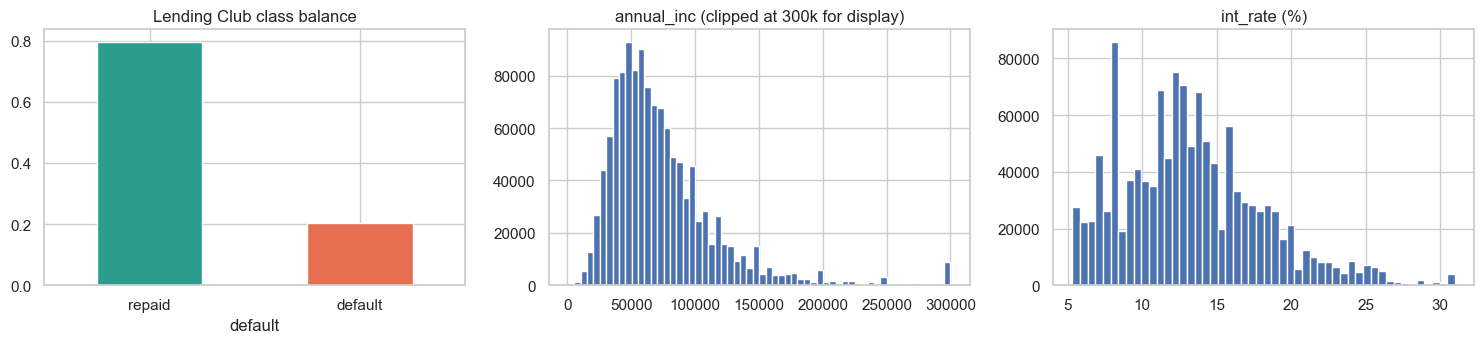

Skew annual_inc raw vs log1p: 47.64 -> 0.21


In [5]:
lc_dq = pd.DataFrame(dq, columns=["issue", "rows_affected", "action"])
display(lc_dq)
display(lc[["loan_amnt", "int_rate", "annual_inc", "dti", "revol_util", "open_acc"]].describe().round(2).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
lc["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Lending Club class balance"); ax[0].set_xticklabels(["repaid", "default"], rotation=0)
ax[1].hist(lc["annual_inc"].clip(upper=300000), bins=60); ax[1].set_title("annual_inc (clipped at 300k for display)")
ax[2].hist(lc["int_rate"], bins=50); ax[2].set_title("int_rate (%)")
plt.tight_layout(); plt.show()
print("Skew annual_inc raw vs log1p:", round(lc["annual_inc"].skew(), 2), "->", round(lc["log_annual_inc"].skew(), 2))

## Result Interpretation — Lending Club data-quality summary
### What did we actually get?
| Issue | Rows affected | Share of closed loans |
|---|---|---|
| Open or censored status | 957,030 | (dropped before the closed count) |
| `dti` < 0 or > 100 | 478 | 0.04% |
| `revol_util` > 100% | 4,537 | 0.35% (clipped at 150) |
| `annual_inc` ≤ 0 | 302 | 0.02% |
| `annual_inc` > $1M | 279 | kept, log-transformed |
| home_ownership ANY/NONE/OTHER | 459 | merged |
| Remaining NaNs | 48,518 | 3.7% (mostly `mort_acc`) |

Exact duplicate rows: **0**. After cleaning: `int_rate` mean 13.30% with SD 4.79, range 5.31–30.99. `dti` now runs 0–100.
* **Skew:** `annual_inc` has mean $76,437 vs median $65,000, a max of $10,999,200, and **skew 47.63, which falls to 0.18 after `log1p`**.
* **Charts:** the class-balance chart shows about 80/20 repaid vs default.
### What does it mean?
* **Income must be logged.** Without the log, a few millionaires would dominate any linear model.
* **Accuracy is a weak metric here.** An "everyone repays" rule already scores about 80%, so later weeks judge models by ROC-AUC, F1 and recall.
* **Cleaning removed about 4% of closed loans,** mostly rows with an incomplete credit history.
### What should we do next?
Run the same audit on the Taiwan dataset.

**Note for this notebook:** the original Week 4 cells below (kept unchanged, with their original outputs) use the raw closed loans with only `dropna`. Part C uses the cleaned `lc` frame. The differences are the dti/income fixes and the `log_annual_inc` transform, which is why Part C's AUC differs slightly from the original cells.

## Cell DQ-5 — Loading the Taiwan credit-card default data
### Why are we doing this?
This is the second dataset. It is a different market (revolving credit cards, Taiwan 2005) with the same question —
who will default — so it lets us check whether conclusions generalize beyond Lending Club.
### What are we doing?
Downloading/caching via `kagglehub` and reading the single CSV. Columns: `LIMIT_BAL` (credit limit, NT$), `SEX`, `EDUCATION`,
`MARRIAGE`, `AGE`, `PAY_0, PAY_2..PAY_6` (repayment status by month, −1 = paid on time, 1..9 = months late),
`BILL_AMT1-6` (statement balances), `PAY_AMT1-6` (amounts paid), and the target `default.payment.next.month`.
### What should we examine after execution?
Shape, data types, and whether the first rows match the documented coding.

In [6]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


## Result Interpretation — Taiwan load
### What did we actually get?
**30,000 rows × 25 columns**: 13 float and 12 integer, with no text columns. Row 1 has `PAY_0 = 2` (two months late) and target = 1 (defaulted). That is an early hint that repayment status carries a strong signal.
### What should we do next?
Check the documented and undocumented category codes.

## Cell DQ-6 — Taiwan nulls, duplicates, undocumented codes, ranges and leakage
### Why are we doing this?
This dataset is famous for **undocumented category codes** (EDUCATION 0/5/6, MARRIAGE 0, PAY = −2). If we left them as-is,
a model would treat them as meaningful groups. We also check duplicates, negative bills, and leakage.
### How does it work?
* Rename `PAY_0` to `PAY_1` so the six months are numbered consistently, and the long target name to `default`.
* Duplicates are checked ignoring `ID` (different IDs with identical 23 features are almost certainly repeated records).
* Undocumented codes are merged into the documented "other" category.
* `PAY_*` is kept **ordinal numeric** (−2 < −1 < 0 < 1 … months late) because the order carries risk information.
* Negative bills (customer overpaid) are real, so we use a **signed log** `sign(x)·log(1+|x|)` that tames skew while keeping the sign.
### What should we examine after execution?
Counts per code, how many rows each issue touches, and the final row count and default rate.

In [7]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Result Interpretation — Taiwan checks
### What did we actually get?
* **Missing values:** 0 null cells, and no duplicate IDs.
* **Duplicates:** **35 duplicate profiles** when ID is ignored. They were dropped.
* **Undocumented codes:**
  * `EDUCATION`: 0 (14 rows), 5 (280) and 6 (51), 345 in total.
  * `MARRIAGE`: 0 (54 rows).
  * `PAY_1`: −2 (2,750 rows) plus a long tail of codes 3–8 that are rare (322 or fewer rows each).
* **Final:** **29,965 rows**, with a **22.13%** default rate.
### What does it mean?
The undocumented codes affect about 1.3% of rows for EDUCATION and MARRIAGE, so merging them into "other" is low-risk. `PAY_* = −2` is common (6,531 clients have it in some month), which is too many to drop. It is best treated as "no balance to pay", ranked below "paid duly".

## Cell DQ-7 — Taiwan data-quality summary, collinearity preview and target balance
### Why are we doing this?
The table documents decisions; the heatmap previews **multicollinearity** among the six monthly bills (which decides whether
regularization/PCR will matter); the default rate by `PAY_1` previews the strongest risk signal.
### What should we examine after execution?
Bill correlations (values near 1 mean near-duplicate predictors), the default-rate gradient across `PAY_1` codes, and skew of `LIMIT_BAL`.

,issue,rows_affected,action
0,Missing values,0,none to handle
1,Duplicate ID,0,none
2,Duplicate rows (ignoring ID),35,dropped (identical profiles)
3,EDUCATION undocumented codes 0/5/6,345,recoded to 4 = other
4,MARRIAGE undocumented code 0,54,recoded to 3 = other
5,"PAY_* = -2 (no consumption, undocumented)",6531,kept as ordinal (-2 < -1 paid duly < 0 revolving)
6,Negative BILL_AMT (credit balance/overpay),1930,kept; signed log transform
7,AGE range 21-79,0,"plausible, kept"
8,Constant columns,0,none
9,Post-outcome columns,0,none: all features precede target month


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,29965.0,167442.0,129760.1,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,29965.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
BILL_AMT1,29965.0,51283.0,73658.1,-165580.0,3595.0,22438.0,67260.0,964511.0
PAY_AMT1,29965.0,5670.1,16571.8,0.0,1000.0,2102.0,5008.0,873552.0
PAY_1,29965.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0


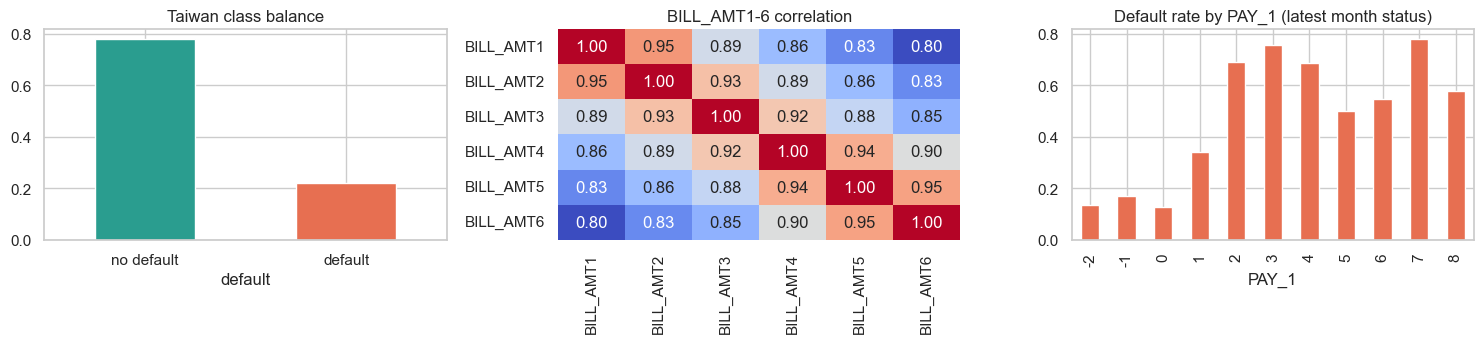

Skew LIMIT_BAL raw vs log: 0.99 -> -0.51


In [8]:
tw_dq = pd.DataFrame(tdq, columns=["issue", "rows_affected", "action"])
display(tw_dq)
display(tw[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_1"]].describe().round(1).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
tw["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Taiwan class balance"); ax[0].set_xticklabels(["no default", "default"], rotation=0)
sns.heatmap(tw[BILL].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], cbar=False)
ax[1].set_title("BILL_AMT1-6 correlation")
tw.groupby("PAY_1")["default"].mean().plot.bar(ax=ax[2], color="#e76f51"); ax[2].set_title("Default rate by PAY_1 (latest month status)")
plt.tight_layout(); plt.show()
print("Skew LIMIT_BAL raw vs log:", round(tw["LIMIT_BAL"].skew(), 2), "->", round(tw["log_LIMIT_BAL"].skew(), 2))

## Result Interpretation — Taiwan data-quality summary
### What did we actually get?
* **Issues table:** 35 duplicates, 345 education recodes, 54 marriage recodes, 6,531 rows with a −2 code, 1,930 rows with a negative bill, ages 21–79, and no leakage columns.
* **Bill correlations:** `BILL_AMT1–6` are strongly correlated. Neighbouring months are near 0.95, and month 1 vs month 6 is about 0.80.
* **Default rate by `PAY_1`:** about 13–17% for codes −2, −1 and 0 (no balance, paid duly, revolving). It rises to **34%** for 1 month late and **69%** for 2 months late, and stays at 50–78% for the rare longer delays.
* **Skew of `LIMIT_BAL`:** 0.99 raw, −0.51 after log.
### What does it mean?
* **Multicollinearity is high here, unlike Lending Club.** Regularization (Week 2) and PCR/PLS (Week 3) should matter much more on this dataset.
* **`PAY_1` is the dominant risk signal.** Any later model that does not rank it highly deserves suspicion.
* **About 22% default,** a similar imbalance to Lending Club, so the same metrics apply.
### What should we do next?
Move to the modeling for this week (Part B).

In [20]:
# Binary target: 1 = default (Charged Off / Default), 0 = repaid (Fully Paid)
df['default'] = df['loan_status'].isin(['Charged Off', 'Default']).astype(int)

# Parse term '36 months' -> 36 (kept as string for one-hot later; numeric copy for inspection)
df['term_months'] = df['term'].str.extract(r'(\d+)').astype(int)

# Keep only modeling columns and drop rows with missing values
df_model = df.dropna(subset=USECOLS).copy().reset_index(drop=True)

print(f"Rows after cleaning: {len(df_model):,}")
print(f"Default rate: {df_model['default'].mean():.4%} ({df_model['default'].sum():,} defaults)")
display(df_model['term'].value_counts().rename_axis('term').to_frame(name='count'))
display(df_model[['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util']].describe().round(2))
feature_desc = pd.DataFrame({
    "feature": ["loan_amnt", "int_rate", "annual_inc", "dti", "open_acc", "revol_util"],
    "description": [
        "Principal loan amount requested by the borrower.",
        "Interest rate on the loan, expressed as a percentage.",
        "Borrower's annual income in dollars.",
        "Debt-to-income ratio, measuring monthly debt obligations relative to income.",
        "Number of open credit accounts.",
        "Revolving credit utilization rate, expressed as a percentage of the credit limit used."
    ]
})
pd.set_option("display.max_colwidth", 200)
display(feature_desc)

Rows after cleaning: 1,302,516
Default rate: 20.0732% (261,456 defaults)


,count
term,
36 months,987934
60 months,314582


,loan_amnt,int_rate,annual_inc,dti,open_acc,revol_util
count,1302516.00,1302516.00,1302516.00,1302516.00,1302516.00,1302516.00
mean,14417.84,13.26,76164.24,18.26,11.60,51.91
std,8697.92,4.76,69982.80,10.94,5.46,24.50
min,500.00,5.31,16.00,-1.00,1.00,0.00
25%,8000.00,9.75,45953.00,11.79,8.00,33.60
50%,12000.00,12.74,65000.00,17.61,11.00,52.30
75%,20000.00,15.99,90000.00,24.04,14.00,70.80
max,40000.00,30.99,10999200.00,999.00,90.00,892.30


,feature,description
0,loan_amnt,Principal loan amount requested by the borrower.
1,int_rate,"Interest rate on the loan, expressed as a percentage."
2,annual_inc,Borrower's annual income in dollars.
3,dti,"Debt-to-income ratio, measuring monthly debt obligations relative to income."
4,open_acc,Number of open credit accounts.
5,revol_util,"Revolving credit utilization rate, expressed as a percentage of the credit limit used."


In [21]:
NUM = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util']
CAT = ['term', 'grade', 'home_ownership', 'purpose', 'verification_status']

# Fixed 60k sample keeps runtime peer-review friendly and reproducible
dfs = df_model.sample(n=min(60000, len(df_model)), random_state=42).reset_index(drop=True)
X = dfs[NUM + CAT]
y = dfs['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}, test default rate: {y_test.mean():.2%}")
# Explicit decision threshold: predict default when P(default) >= THRESHOLD.
# sklearn .predict() hides this as 0.5; we set it ourselves so it is visible and tunable.
THRESHOLD = 0.50
print(f"Decision threshold THRESHOLD = {THRESHOLD} (explicit, not a hidden default)")
prep_unscaled = ColumnTransformer([
    ('num', 'passthrough', NUM),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT),
])
base_pipe = Pipeline([
    ('prep', prep_unscaled),
    ('clf', LogisticRegression(max_iter=1000)),
])
base_pipe.fit(X_train, y_train)
base_prob = base_pipe.predict_proba(X_test)[:, 1]
base_pred = (base_prob >= THRESHOLD).astype(int)  # explicit 0.50 cutoff

print(f"Unscaled: acc={accuracy_score(y_test, base_pred):.4f} "
      f"prec={precision_score(y_test, base_pred):.4f} "
      f"rec={recall_score(y_test, base_pred):.4f} "
      f"f1={f1_score(y_test, base_pred):.4f} "
      f"auc={roc_auc_score(y_test, base_prob):.4f} "
      f"n_iter={base_pipe.named_steps['clf'].n_iter_}")
print("Confusion matrix [TN FP / FN TP]:")
cm_base = confusion_matrix(y_test, base_pred)
display(pd.DataFrame(cm_base, index=['actual repaid', 'actual default'], columns=['pred repaid', 'pred default']))


Train: (48000, 11), Test: (12000, 11), test default rate: 20.14%
Decision threshold THRESHOLD = 0.5 (explicit, not a hidden default)
Unscaled: acc=0.7968 prec=0.4703 rec=0.0687 f1=0.1199 auc=0.6906 n_iter=[1000]
Confusion matrix [TN FP / FN TP]:


,pred repaid,pred default
actual repaid,9396,187
actual default,2251,166


In [22]:
# Fit scalers on TRAIN numerics only (no leakage)
std_scaler = StandardScaler().fit(X_train[NUM])
mm_scaler = MinMaxScaler().fit(X_train[NUM])

print("Before scaling (train means):")
train_means = X_train[NUM].mean().round(2).to_frame(name="mean")
display(train_means)
print("\nAfter StandardScaler (train means ~ 0, stds ~ 1):")
scaled_train = pd.DataFrame(std_scaler.transform(X_train[NUM]), columns=NUM)
summary = pd.DataFrame({
    "mean": scaled_train.mean(),
    "std": scaled_train.std()
}).round(4)
display(summary)
print("\nAfter MinMaxScaler (train min/max):")
mm_tr = pd.DataFrame(mm_scaler.transform(X_train[NUM]), columns=NUM)

min_max_summary = pd.DataFrame({
    "min": mm_tr.min().round(4),
    "max": mm_tr.max().round(4)
})

display(min_max_summary)

Before scaling (train means):


,mean
loan_amnt,14434.23
int_rate,13.23
annual_inc,75815.03
dti,18.20
open_acc,11.61
revol_util,51.86



After StandardScaler (train means ~ 0, stds ~ 1):


,mean,std
loan_amnt,-0.0,1.0
int_rate,0.0,1.0
annual_inc,0.0,1.0
dti,-0.0,1.0
open_acc,-0.0,1.0
revol_util,-0.0,1.0



After MinMaxScaler (train min/max):


,min,max
loan_amnt,0.0,1.0
int_rate,0.0,1.0
annual_inc,0.0,1.0
dti,0.0,1.0
open_acc,0.0,1.0
revol_util,0.0,1.0


In [23]:
def build_pipe(scaler):
    num_step = scaler if scaler is not None else 'passthrough'
    prep = ColumnTransformer([
        ('num', num_step, NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT),
    ])
    return Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=1000))])

results = {}
probs = {}
iters = {}
for name, scaler in [('unscaled', None), ('standard', StandardScaler()), ('minmax', MinMaxScaler())]:
    pipe = build_pipe(scaler)
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= THRESHOLD).astype(int)  # same explicit cutoff as Cell 3
    probs[name] = prob
    iters[name] = pipe.named_steps['clf'].n_iter_[0]
    results[name] = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, prob),
        'n_iter': iters[name],
    }
    if name == 'standard':
        std_pipe = pipe

display(pd.DataFrame(results).T.round(4))

# Odds ratios from the standardized model (1-SD change, comparable across numerics)
feat_names = std_pipe.named_steps['prep'].get_feature_names_out()
coefs = std_pipe.named_steps['clf'].coef_[0]
odds = pd.DataFrame({'feature': feat_names, 'coef': coefs, 'odds_ratio': np.exp(coefs)})
odds['effect'] = np.where(odds['odds_ratio'] > 1, 'higher default odds', 'lower default odds')
print("\nTop 5 positive (higher default odds):")
display(odds.sort_values('odds_ratio', ascending=False).head(5).round(4))
print("\nTop 5 negative (lower default odds):")
display(odds.sort_values('odds_ratio').head(5).round(4))


,accuracy,precision,recall,f1,roc_auc,n_iter
unscaled,0.7968,0.4703,0.0687,0.1199,0.6906,1000.0
standard,0.7982,0.4901,0.0513,0.0929,0.6998,55.0
minmax,0.7986,0.5000,0.0451,0.0827,0.6993,61.0



Top 5 positive (higher default odds):


,feature,coef,odds_ratio,effect
12,cat__grade_G,1.3438,3.8335,higher default odds
11,cat__grade_F,1.2454,3.4744,higher default odds
10,cat__grade_E,1.2067,3.3426,higher default odds
9,cat__grade_D,1.1232,3.0747,higher default odds
8,cat__grade_C,0.8745,2.3977,higher default odds



Top 5 negative (lower default odds):


,feature,coef,odds_ratio,effect
13,cat__home_ownership_MORTGAGE,-0.7578,0.4687,lower default odds
16,cat__home_ownership_OWN,-0.4738,0.6226,lower default odds
30,cat__purpose_wedding,-0.4019,0.6691,lower default odds
22,cat__purpose_house,-0.3947,0.6739,lower default odds
17,cat__home_ownership_RENT,-0.3611,0.6969,lower default odds


DATASET RESULTS
Closed loans after cleaning: 1,302,516
Analysis sample: 60,000 (seed 42), train 48,000 / test 12,000
Default rate overall: 20.07%, test: 20.14%

MODEL RESULTS (test set)


,accuracy,precision,recall,f1,roc_auc,n_iter
unscaled,0.7968,0.4703,0.0687,0.1199,0.6906,1000.0
standard,0.7982,0.4901,0.0513,0.0929,0.6998,55.0
minmax,0.7986,0.5000,0.0451,0.0827,0.6993,61.0



Optimizer iterations: {'unscaled': 1000, 'standard': 55, 'minmax': 61}
(unscaled hitting max_iter=1000 means it did NOT converge; scaled converges in ~50-60.)


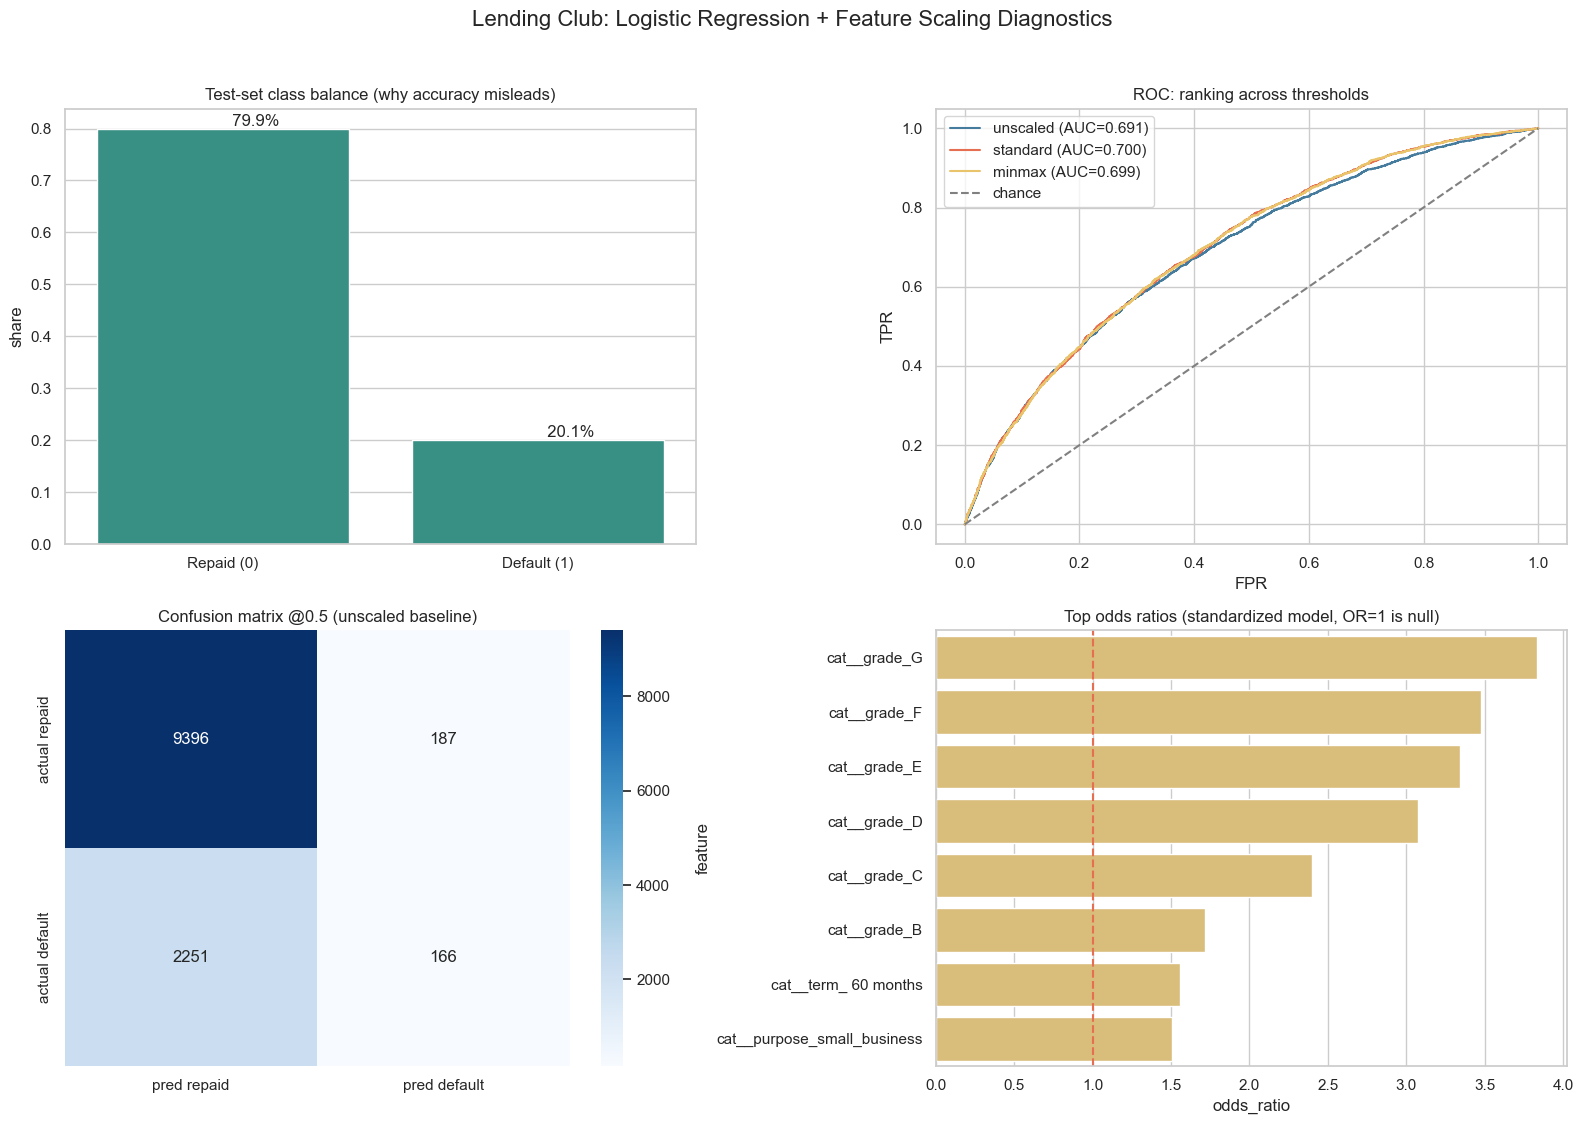


VISUAL INTERPRETATION GUIDE
- Class balance near 80/20: predicting all-repaid gives ~80% accuracy, so judge by precision/recall/F1/AUC.
- ROC curves: overlapping curves mean similar ranking; the scaling win here is convergence (n_iter), not AUC.
- Confusion matrix: low recall means most defaults are missed at 0.5 — threshold tuning or class_weight are follow-ups.
- Odds ratios: OR>1 = higher default odds holding others constant (association, not causation).


In [24]:
print("DATASET RESULTS")
print(f"Closed loans after cleaning: {len(df_model):,}")
print(f"Analysis sample: {len(dfs):,} (seed 42), train {len(X_train):,} / test {len(X_test):,}")
print(f"Default rate overall: {df_model['default'].mean():.2%}, test: {y_test.mean():.2%}")
print("\nMODEL RESULTS (test set)")
display(pd.DataFrame(results).T.round(4))
print(f"\nOptimizer iterations: {iters}")
print("(unscaled hitting max_iter=1000 means it did NOT converge; scaled converges in ~50-60.)")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Lending Club: Logistic Regression + Feature Scaling Diagnostics", fontsize=16, y=1.02)

# (a) class balance
ax = axes[0, 0]
sns.barplot(x=['Repaid (0)', 'Default (1)'], y=[1 - y_test.mean(), y_test.mean()], color="#2a9d8f", ax=ax)
ax.set_title("Test-set class balance (why accuracy misleads)")
ax.set_ylabel("share")
for i, v in enumerate([1 - y_test.mean(), y_test.mean()]):
    ax.text(i, v, f"  {v:.1%}", va="bottom")

# (b) ROC curves
ax = axes[0, 1]
for name, color in [('unscaled', '#457b9d'), ('standard', '#e76f51'), ('minmax', '#e9c46a')]:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})", color=color)
ax.plot([0, 1], [0, 1], '--', color='gray', label='chance')
ax.set_title("ROC: ranking across thresholds")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend()

# (c) confusion matrices at 0.5
ax = axes[1, 0]
base_test_prob = base_pipe.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (base_test_prob >= THRESHOLD).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['pred repaid', 'pred default'], yticklabels=['actual repaid', 'actual default'])
ax.set_title(f"Confusion matrix @{THRESHOLD} (unscaled baseline)")

# (d) top odds ratios (standardized model)
ax = axes[1, 1]
top = odds.reindex(odds['odds_ratio'].sort_values(ascending=False).index[:8])
sns.barplot(x='odds_ratio', y='feature', data=top, color="#e9c46a", ax=ax)
ax.axvline(1, color="#e76f51", linestyle='--')
ax.set_title("Top odds ratios (standardized model, OR=1 is null)")

plt.tight_layout()
plt.show()

print("\nVISUAL INTERPRETATION GUIDE")
print("- Class balance near 80/20: predicting all-repaid gives ~80% accuracy, so judge by precision/recall/F1/AUC.")
print("- ROC curves: overlapping curves mean similar ranking; the scaling win here is convergence (n_iter), not AUC.")
print("- Confusion matrix: low recall means most defaults are missed at 0.5 — threshold tuning or class_weight are follow-ups.")
print("- Odds ratios: OR>1 = higher default odds holding others constant (association, not causation).")


## Conclusion
We asked: can loan data predict who will default? We used 60,000 closed Lending Club loans (about 20% defaulted).

What we found:
- Loan grade matters most. Grade G loans have roughly 4x the default odds of grade A loans. Lower grades mean riskier borrowers.
- Homeowners (mortgage or own) default less than others.
- Scaling the numbers (StandardScaler) made training about 18x faster (55 steps instead of 1000) but did not change accuracy much (AUC about 0.70).
- At the 0.50 cutoff the model is too careful: out of 2,417 real defaults it catches only 166 (about 1 in 15). It is good at ranking risky borrowers but bad at flagging them with this cutoff.

What this means for business: do not use 0.50 as-is. Lower the cutoff (for example 0.30) or balance the classes before saying yes or no to a loan.

Limit: this is one 60k sample with default settings, so it shows patterns (association), not proof of cause.


---
# Part C — Fixing the 0.5-threshold problem: class weights, cross-validated tuning and threshold choice (both datasets)
The original analysis above ended with a key weakness: at the default 0.5 cutoff the model caught only about 1 in 15 defaults
(recall 0.05, F1 0.09). That is not a modeling failure but a **decision-rule** failure: with 20% defaults, few loans ever reach a
50% predicted probability. Part C fixes it properly and repeats everything on the Taiwan data:
1. `class_weight="balanced"`, which reweights the loss so a missed default costs about 4× a false alarm.
2. **5-fold stratified `GridSearchCV`** over the regularization strength `C` and the penalty (L1/L2).
3. **Threshold tuning on out-of-fold training predictions** (never on the test set).
4. Taiwan: unscaled vs scaled, then the same tuning.

**Hypotheses for the coefficient tests:** H₀: βⱼ = 0 (feature unrelated to the log-odds of default) vs H₁: βⱼ ≠ 0, α = 0.05.
For model comparison we use ROC-AUC (ranking quality; 0.5 = random, 1.0 = perfect) and PR-AUC (precision–recall area; the
random baseline equals the default rate, about 0.20–0.22).

## Cell C1 — Shared classification setup (identical in Weeks 4, 5 and 6)
### Why are we doing this?
To compare logistic regression, SVM, decision trees and random forests fairly, every week must use the **same rows, the same
features and the same test set**. This cell defines them once; Weeks 5 and 6 contain an identical copy.
### What are we doing?
* **Lending Club:** a 60,000-loan random sample of the clean closed loans (seed 42), split 80/20 **stratified** on `default`, so both parts keep the about 20% default rate.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.
* `make_prep(num, cat, scale=True)` returns a `ColumnTransformer`. Numerics are standardized and categoricals one-hot encoded. It is always fit inside a pipeline on training folds only, so no test-set leakage.
### Key concept — stratification
With 20–22% positives, a random split could, by chance, put noticeably more defaults in one part. Stratifying guarantees equal rates, which makes metrics comparable between train and test.
### What should we examine after execution?
Train/test sizes and that the default rates match between splits.

In [14]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
FIG = "../../../week_10092026_w7/DX799O1/figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = ["log_LIMIT_BAL", "AGE"] + [f"PAY_{i}" for i in range(1, 7)] + [f"log_BILL_AMT{i}" for i in range(1, 7)] + [f"log_PAY_AMT{i}" for i in range(1, 7)]
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2, stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2, stratify=tw["default"], random_state=SEED)
DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan": (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scale=True):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob), "threshold": thr}

for name, (a, b, ya, yb, num, cat) in DATA.items():
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%} | numeric {len(num)}, categorical {len(cat)}")

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3


## Result Interpretation — Shared classification setup
### What did we actually get?
* **Lending Club:** train 48,000 × 11 and test 12,000 × 11. Both have a **20.29%** default rate, with 6 numeric and 5 categorical features.
* **Taiwan:** train 23,972 × 23 and test 5,993 × 23. Both are at **22.13%** default, with 20 numeric and 3 categorical features.
### What does it mean?
* **Stratification worked.** The default rates are identical across splits, so every later metric is comparable between train and test, and across weeks.
* **Baselines to beat:**
  * Accuracy: an "everyone repays" rule scores **79.7%** on Lending Club and **77.9%** on Taiwan.
  * PR-AUC: a random ranking scores **0.203** and **0.221**.

## Cell C2 — Lending Club: unweighted vs class-weighted logistic regression
### Why are we doing this?
To show separately what reweighting does. `class_weight="balanced"` multiplies each default's contribution to the
log-loss by n/(2·n_default) ≈ 2.5 and each repaid loan's by ≈ 0.63, which pushes predicted probabilities upward for risky loans.
### What should we examine after execution?
* Whether recall and F1 rise at the 0.5 cutoff.
* Whether ROC-AUC stays about the same. It should, because reweighting mostly *shifts* probabilities rather than re-ranking loans.
* PR-AUC compared with the 0.20 baseline.

In [15]:
Xa, Xb, ya, yb, num, cat = DATA["Lending Club"]
rows = {}
for cw in [None, "balanced"]:
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", LogisticRegression(max_iter=2000, class_weight=cw))]).fit(Xa, ya)
    rows[f"class_weight={cw}"] = scores(yb, pipe.predict_proba(Xb)[:, 1])
display(pd.DataFrame(rows).T.round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
class_weight=None,0.7988,0.5376,0.0616,0.1105,0.7124,0.3783,0.5
class_weight=balanced,0.6437,0.3212,0.6793,0.4362,0.7126,0.3779,0.5


## Result Interpretation — Effect of class weights (Lending Club, threshold 0.5)
### What did we actually get?
| | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Unweighted | 0.7988 | 0.5376 | **0.0616** | 0.1105 | 0.7124 | 0.3783 |
| `balanced` | 0.6437 | 0.3212 | **0.6793** | **0.4362** | 0.7126 | 0.3779 |
### How should we interpret the numbers?
* **The unweighted model barely beats "predict nobody defaults".** Its 79.9% accuracy is close to the 79.7% baseline, because it flags almost nobody: recall is 6%, so 94% of defaults are missed.
* **Reweighting raises recall to 68% and F1 nearly fourfold** (0.11 → 0.44). Accuracy falls to 64% because many more good loans are flagged (precision 0.32, so about 1 in 3 flagged loans actually defaults).
* **ROC-AUC (0.712) and PR-AUC (0.378) are unchanged.** Reweighting does not make the model *better at ranking* risk; it moves where the 0.5 line falls. PR-AUC of 0.378 is 1.9× the 0.203 random baseline.
### What can we conclude?
* **The original notebook's low recall** (0.05) came from the decision rule, not from a lack of signal.
* **Which side to favour is a business choice.** For a lender, missing a default (losing principal) usually costs several times more than declining a good borrower, so the high-recall side is the relevant one.

## Cell C3 — GridSearchCV over C and penalty (Lending Club and Taiwan)
### Why are we doing this?
`C` is the **inverse** regularization strength: small C means a strong penalty (simpler model, more bias); large C means a weak penalty (closer to plain maximum likelihood, more variance).
L1 can zero out dummy columns (feature selection); L2 shrinks all of them smoothly. We pick the combination with the best mean 5-fold CV **ROC-AUC**.
We use AUC because it judges the ranking of risk independently of any threshold, and choose the threshold separately in the next cell.
### How does it work?
`GridSearchCV` refits the full pipeline (scaler + encoder + model) inside each fold, so the scaler never sees the validation fold.
The grid is 5 values of C × 2 penalties = 10 candidates × 5 folds = 50 fits per dataset, using the `liblinear` solver, which supports both penalties.
### Alternatives
`RandomizedSearchCV` for larger grids; `LogisticRegressionCV` (built-in CV over C).
### What should we examine after execution?
* The mean ± SD CV AUC of each candidate. A small SD means a stable estimate.
* How flat the AUC curve is across C.
* How many coefficients L1 sets to zero.

In [16]:
grid = {"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"]}
best_lr = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000))])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=CV5, n_jobs=-1).fit(Xa, ya)
    best_lr[name] = gs
    cvr = pd.DataFrame(gs.cv_results_)[["param_clf__C", "param_clf__penalty", "mean_test_score", "std_test_score", "rank_test_score"]]
    print(f"\n{name}: best {gs.best_params_}  CV AUC {gs.best_score_:.4f}")
    display(cvr.sort_values(["param_clf__penalty", "param_clf__C"]).round(4).reset_index(drop=True))
    coef = gs.best_estimator_.named_steps["clf"].coef_[0]
    print(f"non-zero coefficients: {(coef != 0).sum()} of {coef.size}")


Lending Club: best {'clf__C': 1, 'clf__penalty': 'l1'}  CV AUC 0.7034


,param_clf__C,param_clf__penalty,mean_test_score,std_test_score,rank_test_score
0,0.001,l1,0.6880,0.0056,10
1,0.010,l1,0.7006,0.0053,8
2,0.100,l1,0.7029,0.0047,6
3,1.000,l1,0.7034,0.0046,1
4,10.000,l1,0.7033,0.0045,3
5,0.001,l2,0.7001,0.0053,9
6,0.010,l2,0.7023,0.0049,7
7,0.100,l2,0.7031,0.0046,5
8,1.000,l2,0.7033,0.0045,2
9,10.000,l2,0.7033,0.0045,4


non-zero coefficients: 28 of 30



Taiwan: best {'clf__C': 0.001, 'clf__penalty': 'l2'}  CV AUC 0.7517


,param_clf__C,param_clf__penalty,mean_test_score,std_test_score,rank_test_score
0,0.001,l1,0.7272,0.0116,10
1,0.010,l1,0.7491,0.0094,9
2,0.100,l1,0.7514,0.0095,8
3,1.000,l1,0.7514,0.0097,6
4,10.000,l1,0.7514,0.0097,5
5,0.001,l2,0.7517,0.0086,1
6,0.010,l2,0.7514,0.0093,7
7,0.100,l2,0.7515,0.0096,2
8,1.000,l2,0.7514,0.0097,3
9,10.000,l2,0.7514,0.0097,4


non-zero coefficients: 26 of 26


## Result Interpretation — CV grid over C and penalty
### What did we actually get?
**Lending Club:**
* **Best: C = 1, L1, with CV AUC 0.7034 ± 0.0046.**
* Every candidate from C = 0.01 to 10 is within 0.003 of it (0.7006–0.7034), which is less than one fold-SD.
* Only C = 0.001 is clearly worse (L1 0.6880).
* L1 keeps **28 of 30** coefficients.

**Taiwan:**
* **Best: C = 0.001, L2, with CV AUC 0.7517 ± 0.0086.**
* It is statistically tied with all of C = 0.01–10 (0.7514–0.7515).
* Only L1 at C = 0.001 is clearly worse (0.7272), because that strong a lasso penalty removes useful features.
### How should we interpret the numbers?
* **The AUC surface is flat.** Regularization strength barely matters once the penalty is not extreme. With 24k–48k rows and only 26–30 coefficients, the unpenalized fit is already stable. This is the same finding as Week 2 for regression.
* **The fold SD (0.005–0.01) is larger than the differences between candidates,** so the "best" pick is essentially a tie. Reporting mean ± SD rather than only the best mean is what reveals this.
* **Taiwan's preferred C = 0.001 is a very strong L2 penalty.** It works because the PAY and bill blocks are collinear, so heavy shrinkage of correlated coefficients costs nothing.

## Cell C4 — Choosing the decision threshold on out-of-fold predictions
### Why are we doing this?
A lender does not need "probability ≥ 0.5"; it needs a cutoff that balances missed defaults (false negatives, which cost lost
principal) against declined good borrowers (false positives, which cost lost interest income). We choose the cutoff that
maximizes **F1** on **out-of-fold** predictions for the training set (`cross_val_predict`), then apply it unchanged to the test set.
Choosing it on the test set would be leakage, and the test score would be optimistic.
### What should we examine after execution?
* The chosen threshold for each dataset.
* Test precision, recall and F1 at 0.5 compared with the tuned cutoff.
* The confusion matrices.


Lending Club: F1-optimal out-of-fold threshold = 0.510


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.6438,0.3212,0.6784,0.4359,0.7126,0.3782,0.5000
at tuned 0.510,0.6527,0.3236,0.6530,0.4328,0.7126,0.3782,0.5098


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[6242, 3323], [845, 1590]]



Taiwan: F1-optimal out-of-fold threshold = 0.540


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.7272,0.4207,0.6184,0.5008,0.741,0.4993,0.5000
at tuned 0.540,0.7586,0.4629,0.5694,0.5107,0.741,0.4993,0.5396


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[3791, 876], [571, 755]]


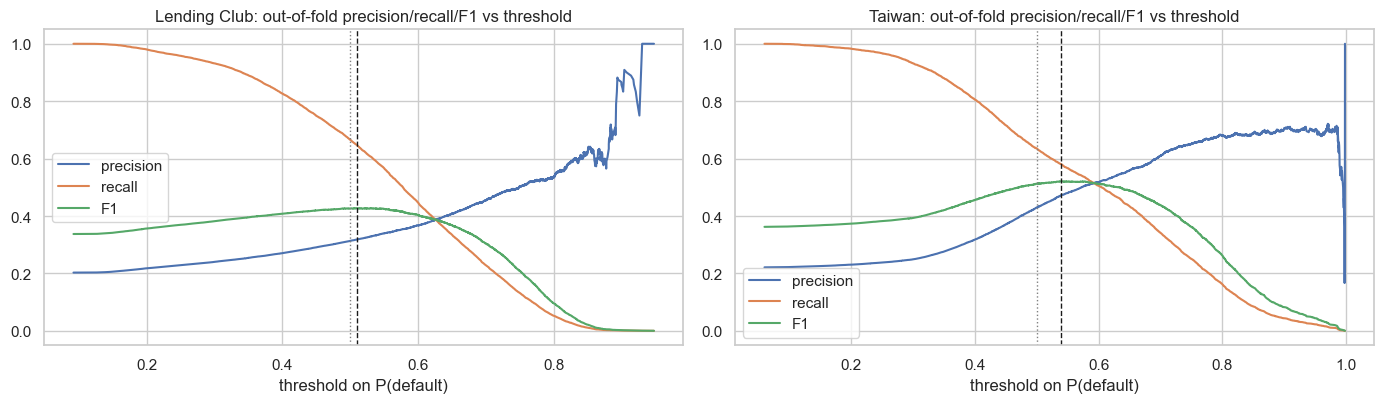

In [17]:
lr_final = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (name, (Xa, Xb, ya, yb, num, cat)) in zip(axes, DATA.items()):
    est = best_lr[name].best_estimator_
    oof = cross_val_predict(est, Xa, ya, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, th = precision_recall_curve(ya, oof)
    f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    thr = float(th[np.argmax(f1s)])
    prob = est.predict_proba(Xb)[:, 1]
    lr_final[name] = {"at 0.5": scores(yb, prob, 0.5), f"at tuned {thr:.3f}": scores(yb, prob, thr)}
    print(f"\n{name}: F1-optimal out-of-fold threshold = {thr:.3f}")
    display(pd.DataFrame(lr_final[name]).T.round(4))
    cm = confusion_matrix(yb, (prob >= thr).astype(int))
    print("Confusion matrix at tuned threshold [[TN FP] [FN TP]]:", cm.tolist())
    ax.plot(th, p[:-1], label="precision"); ax.plot(th, r[:-1], label="recall"); ax.plot(th, f1s, label="F1")
    ax.axvline(thr, color="k", ls="--", lw=1); ax.axvline(0.5, color="grey", ls=":", lw=1)
    ax.set_xlabel("threshold on P(default)"); ax.set_title(f"{name}: out-of-fold precision/recall/F1 vs threshold"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w4_threshold.png", dpi=150, bbox_inches="tight"); plt.show()

## Result Interpretation — Threshold chosen on out-of-fold predictions
### What did we actually get?
**Lending Club:**
* The F1-optimal cutoff is **0.510**.
* Test results at that cutoff: precision 0.324, recall 0.653, **F1 0.433**. At 0.5 they are 0.321 / 0.678 / 0.436.
* Confusion matrix: TN 6,242, FP 3,323, FN 845, TP 1,590.

**Taiwan:**
* The cutoff is **0.540**.
* Test results: precision 0.463, recall 0.569, **F1 0.511**, accuracy 0.759, compared with F1 0.501 at 0.5.
* Confusion matrix: TN 3,791, FP 876, FN 571, TP 755.
### How should we interpret the numbers?
* **Balanced weights already move the optimum to about 0.5.** Once the classes are reweighted, the F1-optimal cutoff sits near 0.5, so tuning adds little on Lending Club and about 1 F1 point on Taiwan. Threshold choice and class weighting are two routes to the same goal. Doing both, as here, shows that one is enough.
* **Reading the Lending Club confusion matrix:**
  * The model catches **1,590 of 2,435 defaults (65%)**.
  * It also declines **3,323 of 9,565 good borrowers (35%)**.
  * That is the price of the 0.71 AUC ceiling.
* **Taiwan separates better** (AUC 0.741, PR-AUC 0.499 vs a 0.221 baseline), consistent with the strong `PAY_1` signal found in the data-quality step.
* **Plot:** precision rises and recall falls as the threshold increases. F1 peaks in a broad plateau, so a cutoff anywhere from about 0.45 to 0.6 gives similar F1.
### What can we NOT conclude?
* **That F1 is the right business objective.** A cost-weighted threshold (for example, a missed default costs 5× a lost customer) would choose a lower cutoff.

## Cell C5 — Taiwan: feature scaling (unscaled vs StandardScaler) and odds ratios
### Why are we doing this?
This repeats the original Week 4 scaling experiment on the second dataset. Taiwan's numerics range from `PAY_1` (−2 to 8) to
`log_LIMIT_BAL` (about 9–14), so the scale differences are smaller than in raw Lending Club. That lets us test whether scaling matters less when features are already on similar scales.
The odds ratios (e^β per 1 SD) of the scaled model show the strongest associations.
### What should we examine after execution?
Optimizer iterations (convergence), ROC-AUC unscaled vs scaled, and the largest odds ratios.

In [18]:
Xa, Xb, ya, yb, num, cat = DATA["Taiwan"]
tw_scale = {}
for label, sc in [("unscaled", False), ("standard", True)]:
    pipe = Pipeline([("prep", make_prep(num, cat, scale=sc)), ("clf", LogisticRegression(max_iter=1000))]).fit(Xa, ya)
    tw_scale[label] = {**scores(yb, pipe.predict_proba(Xb)[:, 1]), "n_iter": int(pipe.named_steps["clf"].n_iter_[0])}
    if sc: tw_std = pipe
display(pd.DataFrame(tw_scale).T.round(4))
names = tw_std.named_steps["prep"].get_feature_names_out()
orr = pd.DataFrame({"feature": names, "coef": tw_std.named_steps["clf"].coef_[0]})
orr["odds_ratio"] = np.exp(orr["coef"])
display(orr.reindex(orr["coef"].abs().sort_values(ascending=False).index).head(8).round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,n_iter
unscaled,0.8074,0.6777,0.2474,0.3624,0.7402,0.5072,0.5,554.0
standard,0.8078,0.6783,0.2496,0.3649,0.7401,0.5073,0.5,31.0


,feature,coef,odds_ratio
23,cat__EDUCATION_4,-1.0226,0.3597
2,num__PAY_1,0.5154,1.6744
25,cat__MARRIAGE_3,-0.2083,0.8119
24,cat__MARRIAGE_2,-0.1820,0.8336
14,num__log_PAY_AMT1,-0.1623,0.8502
16,num__log_PAY_AMT3,-0.1595,0.8525
15,num__log_PAY_AMT2,-0.1592,0.8529
0,num__log_LIMIT_BAL,-0.1310,0.8772


## Result Interpretation — Taiwan scaling and odds ratios
### What did we actually get?
* **Unscaled:** 554 iterations, AUC 0.7402.
* **Standardized:** **31 iterations**, AUC 0.7401, with all other metrics within 0.003.
* **Largest effects (standardized model):**
  * `EDUCATION_4` ("other") OR 0.36
  * **`PAY_1` OR 1.67 per SD** (+1 SD ≈ +1.1 months of delay)
  * `MARRIAGE_3` 0.81
  * `log_PAY_AMT1–3` about 0.85 each
  * `log_LIMIT_BAL` 0.88
### What does it mean?
* **Scaling changes optimization speed, not accuracy.** It sped convergence 18× (554 → 31 iterations). This matches Lending Club in the original cells (1,000+ → 55). With L2 regularization, scaling also determines *which* coefficients get penalized; that only matters when the penalty is strong.
* **Payment history dominates Taiwan risk.** The latest month's delay status raises the odds of default by about 67% per SD. Clients who paid more in recent months, and clients with higher limits (which the bank granted to lower-risk customers), have lower odds.
* **The `EDUCATION_4` odds ratio is unreliable.** It rests on only 468 recoded clients, so it is imprecise and should not be read as a real education effect.
### What can we NOT conclude?
* **Causation:** a higher credit limit does not *cause* lower default. The bank assigned high limits to clients it already judged to be safe.

## Cell C6 — Week 4 summary table (used in the Milestone One report)

In [19]:
summ = []
for name in DATA:
    for k, v in lr_final[name].items():
        summ.append({"dataset": name, "model": f"LogReg {best_lr[name].best_params_}", "rule": k, **v})
w4_summary = pd.DataFrame(summ)
display(w4_summary.round(4))

,dataset,model,rule,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
0,Lending Club,"LogReg {'clf__C': 1, 'clf__penalty': 'l1'}",at 0.5,0.6438,0.3212,0.6784,0.4359,0.7126,0.3782,0.5000
1,Lending Club,"LogReg {'clf__C': 1, 'clf__penalty': 'l1'}",at tuned 0.510,0.6527,0.3236,0.6530,0.4328,0.7126,0.3782,0.5098
2,Taiwan,"LogReg {'clf__C': 0.001, 'clf__penalty': 'l2'}",at 0.5,0.7272,0.4207,0.6184,0.5008,0.7410,0.4993,0.5000
3,Taiwan,"LogReg {'clf__C': 0.001, 'clf__penalty': 'l2'}",at tuned 0.540,0.7586,0.4629,0.5694,0.5107,0.7410,0.4993,0.5396


## Result Interpretation — Week 4 summary and conclusion
### What can we conclude?
* **Best tuned logistic regression:**
  * Lending Club: ROC-AUC **0.713**, PR-AUC 0.378, F1 0.43–0.44, recall 0.65–0.68.
  * Taiwan: ROC-AUC **0.741**, PR-AUC 0.499, F1 0.50–0.51.
* **What fixed the problem was class weighting, not tuning.** Weighting fixed the original recall problem (0.05 → 0.68). Tuning C and the penalty barely mattered (a flat CV surface).
* **Feature scaling** is about convergence (18–20× faster) rather than accuracy.
### What should we do next?
* **Week 5:** test whether a margin-based classifier (SVM) or a nonlinear kernel can break the about 0.71/0.74 AUC ceiling.
* **Week 6:** do the same with tree ensembles.
* **Baseline:** these logistic results are the interpretable baseline for the final comparison.